**Abstract**

Sloan Digital Sky Survey (SDSS) have cataloged hundreds of millions of celestial objects using a five-band optical photometric system (`u, g, r, i, z`) [1]. Because obtaining spectroscopic redshift measurements requires resource-intensive follow-up observations, accurately screening celestial targets from broadband photometry alone remains a central challenge in observational astronomy. In this project, we investigate the predictive structure and physical boundaries of SDSS `UGRIZ` photometry using the "Stellar Classification Dataset - SDSS17" from Kaggle through three hypothesis-driven experiments: (1) demonstrating with Decision Trees that pairwise differences between adjacent filter bands mitigate distance-induced flux attenuation and substantially improve stellar classification [2]; (2) revealing via Principal Component Analysis (PCA) that `UGRIZ` photometry spans an approximately two-dimensional manifold governed by overall brightness and spectral color slope, while class boundaries remain non-linear; and (3) training a Multi-Layer Perceptron (MLP) on standardized `UGRIZ` and color-difference features to classify quasars without redshift data. Our neural network achieves strong global performance (81.71% precision, 80.62% recall, ROC-AUC = 0.9677, and PR-AUC = 0.8953), while targeted error and Euclidean-distance analyses on rare high-redshift quasars ($5 < z < 6$, 33.33% recall) confirm the fundamental optical color degeneracy with cool galactic M-dwarfs.


### Background & Research Question Statement

Modern observational astronomy has transitioned into a data-intensive discipline. Large-scale sky surveys, such as the Sloan Digital Sky Survey (SDSS), have cataloged hundreds of millions of celestial objects using a specialized five-band optical photometric system (**UGRIZ**: `u, g, r, i, z`) covering wavelengths from $3000\text{Å}$ to $11000\text{Å}$. As established in foundational literature, these five filters are not arbitrary; they are strategically designed to capture distinct spectral features (such as the Balmer break and ultraviolet excess) while minimizing atmospheric and night-sky emission contaminationp[1].

However, a critical bottleneck exists in the astronomical observation pipeline: while imaging photometry (`UGRIZ`) is relatively inexpensive to collect across wide sky areas, obtaining precise **spectroscopic redshift** requires resource-intensive fiber-optic follow-up. Therefore, celestial targets must first be accurately screened using photometric measurements alone.

**Core Research Question:**  
> *In the absence of expensive spectroscopic redshift data, to what extent can feature engineering (photometric color differences) and non-linear machine learning models extract hidden patterns from SDSS `UGRIZ` photometry to separate stars and identify elusive quasars—particularly high-redshift quasars ($5 < z < 6$)?*

To answer this question, we design three progressive experiments:
1. **Experiment 1 (Feature Engineering):** Verify whether adjacent band differences (color indices) improve stellar classification by mitigating distance-induced flux attenuation.
2. **Experiment 2 (Dimensionality & Separability):** Investigate the intrinsic rank and linear separability of `UGRIZ` and astrometric features using PCA.
3. **Experiment 3 (Non-Linear Classification & High-$z$ Analysis):** Train a Multi-Layer Perceptron (MLP) on `UGRIZ` and color-difference features to classify quasars without redshift, followed by a targeted error analysis on high-redshift quasars ($5 < z < 6$).


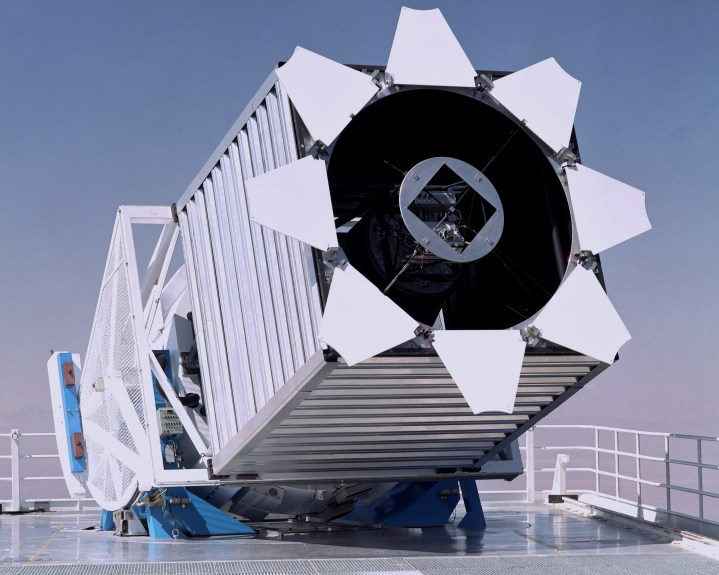

Telescope of SDSS. Image source: https://www.sdss.org/instruments/

In [ ]:
import kagglehub
import numpy as np
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import torch
import torch.nn as nn
import copy

In [ ]:
RANDOM_SEED = 4010
np.random.seed(RANDOM_SEED)

# Stellar classification dataset, can be accessed from https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17.
path = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
data = pd.read_csv(path + "/star_classification.csv")
data = data[(data["u"] > -999) & (data["g"] > -999) & (data["z"] > -999)].reset_index(drop=True)
data.head()

Using Colab cache for faster access to the 'stellar-classification-dataset-sdss17' dataset.


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


---
## Experiment 1: Effectiveness of Photometric Band Differences

### Hypothesis 1
**Providing pairwise differences between adjacent filter magnitudes (`u-g, g-r, r-i, i-z`) improves stellar classification performance compared to using raw `UGRIZ` magnitudes alone.**

* **Physical Motivation:** Inspired by Lenz et al.[2], raw apparent magnitudes depend heavily on an object's distance from Earth. Two stars with identical intrinsic chemical compositions and temperatures will exhibit different raw `UGRIZ` values if located at different distances. Because distance dims light roughly uniformly across optical wavelengths, taking differences between adjacent filter bands cancels out much of this distance effect, isolating intrinsic spectral slopes (color indices).

### Experimental Setup
* **Data Preprocessing & Split:** We sample 30% of the cleaned dataset for computational efficiency and perform a **70% / 30% train-test split**.
* **Feature Sets:**
  1. *Baseline Feature Set (`UGRIZ`):* 5 raw photometric bands (`u, g, r, i, z`).
  2. *Augmented Feature Set:* 9 features combining the 5 raw bands and 4 adjacent band differences (`u-g, g-r, r-i, i-z`).
* **Target & Model:** Binary classification (`1` = `STAR`, `0` = `GALAXY` or `QSO`). We train two Gini-impurity Decision Tree classifiers with fixed structural constraints (`max_depth=5`, `max_leaf_nodes=16`) to ensure a fair comparison.


In [ ]:
#Experiment 1

exp1_data = data.sample(frac=0.3, random_state=RANDOM_SEED, ignore_index=True)

exp1_label = exp1_data["class"].map({"GALAXY":0,"QSO":0,"STAR":1}).to_numpy()
exp1_X_ugriz = exp1_data[["u","g","r","i","z"]].to_numpy()
exp1_X_augmented = np.concat((exp1_X_ugriz,(exp1_X_ugriz[:,:-1] - exp1_X_ugriz[:,1:])),axis=1)

TRAIN_INDEX = (int)(len(exp1_X_ugriz) * 0.7)
exp1_X_ugriz_train = exp1_X_ugriz[:TRAIN_INDEX]
exp1_X_augmented_train = exp1_X_augmented[:TRAIN_INDEX]
exp1_X_ugriz_test = exp1_X_ugriz[TRAIN_INDEX:]
exp1_X_augmented_test = exp1_X_augmented[TRAIN_INDEX:]
exp1_label_train = exp1_label[:TRAIN_INDEX]
exp1_label_test = exp1_label[TRAIN_INDEX:]

exp1_model_ugriz = sklearn.tree.DecisionTreeClassifier(criterion='gini',max_depth=5,max_leaf_nodes=16)
exp1_model_augmented = sklearn.tree.DecisionTreeClassifier(criterion='gini',max_depth=5,max_leaf_nodes=16)

exp1_model_ugriz.fit(exp1_X_ugriz_train,exp1_label_train)
exp1_model_augmented.fit(exp1_X_augmented_train,exp1_label_train)

DecisionTreeClassifier(max_depth=5, max_leaf_nodes=16)

In [ ]:
exp1_label_predicted_ugriz = exp1_model_ugriz.predict(exp1_X_ugriz_test)
exp1_label_predicted_augmented = exp1_model_augmented.predict(exp1_X_augmented_test)

exp1_mse_ugriz_test = ((exp1_label_predicted_ugriz - exp1_label_test) ** 2).mean()
exp1_mse_augmented_test = ((exp1_label_predicted_augmented - exp1_label_test) ** 2).mean()
exp1_recall_ugriz_test = sklearn.metrics.recall_score(exp1_label_test,exp1_label_predicted_ugriz)
exp1_recall_augmented_test = sklearn.metrics.recall_score(exp1_label_test,exp1_label_predicted_augmented)
exp1_precision_ugriz_test = sklearn.metrics.precision_score(exp1_label_test,exp1_label_predicted_ugriz)
exp1_precision_augmented_test = sklearn.metrics.precision_score(exp1_label_test,exp1_label_predicted_augmented)
exp1_confusion_matrix_ugriz_test = sklearn.metrics.confusion_matrix(exp1_label_test,exp1_label_predicted_ugriz)
exp1_confusion_matrix_augmented_test = sklearn.metrics.confusion_matrix(exp1_label_test,exp1_label_predicted_augmented)

exp1_mse_baseline = ((0 - exp1_label_test) ** 2).mean()
exp1_recall_baseline = sklearn.metrics.recall_score(exp1_label_test,np.zeros(len(exp1_label_test)))
exp1_precision_baseline = sklearn.metrics.precision_score(exp1_label_test,np.zeros(len(exp1_label_test)))
exp1_confusion_matrix_baseline = sklearn.metrics.confusion_matrix(exp1_label_test,np.zeros(len(exp1_label_test)))

np.random.seed(RANDOM_SEED)
random_prediction = np.random.randint(0,2,len(exp1_label_test))
exp1_mse_random = ((random_prediction - exp1_label_test) ** 2).mean()
exp1_recall_random = sklearn.metrics.recall_score(exp1_label_test,random_prediction)
exp1_precision_random = sklearn.metrics.precision_score(exp1_label_test,random_prediction)
exp1_confusion_matrix_random = sklearn.metrics.confusion_matrix(exp1_label_test,random_prediction)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.



### Evaluation Metrics
We evaluate the models using **Mean Squared Error (MSE)**, **Precision**, and **Recall**. Because non-star objects (`GALAXY` and `QSO`) form the majority class (~78%), standard accuracy can be misleading due to dominant true negatives. Therefore, we compare both Decision Trees against two reference benchmarks:
1. **Majority-Class Baseline:** A naive classifier that always predicts `0` ("Not Star").
2. **Random Baseline:** A classifier generating uniform random binary predictions.


-----Metrics-----
MSE:
The mse of ugriz model is  0.18233333333333332
The mse of augmented model is  0.12122222222222222
The mse of majority-class baseline model is  0.211
The mse of random model is  0.503

PRECISION:
The precision of ugriz model is  0.6151785714285715
The precision of augmented model is  0.8122102009273571
The precision of majority-class baseline model is  0.0
The precision of random model is  0.20864745011086475

RECALL:
The recall of ugriz model is  0.36282253817798843
The recall of augmented model is  0.5534491837809373
The recall of majority-class baseline model is  0.0
The recall of random model is  0.4955239599789363

CONFUSION MATRIX
The confusion matrix of ugriz model
The confusion matrix of augmented model
The confusion matrix of majority-class baseline model
The confusion matrix of random model


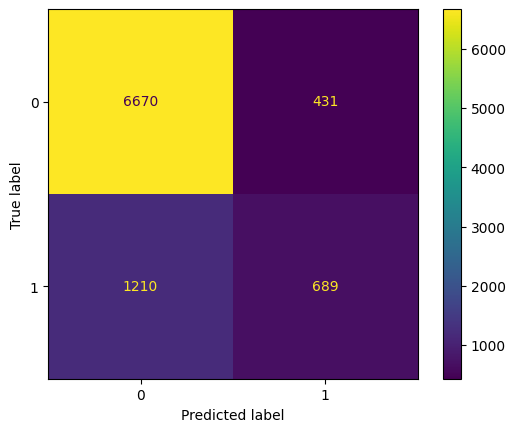

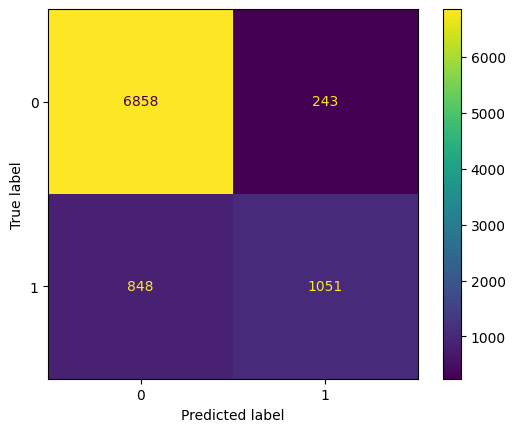

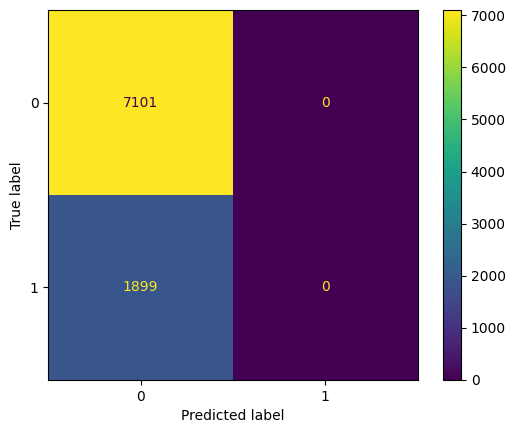

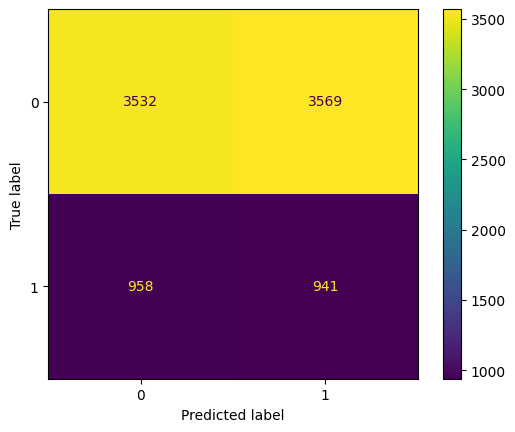

In [ ]:
print("-----Metrics-----")
print("MSE:")
print("The mse of ugriz model is ",exp1_mse_ugriz_test)
print("The mse of augmented model is ",exp1_mse_augmented_test)
print("The mse of majority-class baseline model is ",exp1_mse_baseline)
print("The mse of random model is ",exp1_mse_random)
print()
print("PRECISION:")
print("The precision of ugriz model is ",exp1_precision_ugriz_test)
print("The precision of augmented model is ",exp1_precision_augmented_test)
print("The precision of majority-class baseline model is ",exp1_precision_baseline)
print("The precision of random model is ",exp1_precision_random)
print()
print("RECALL:")
print("The recall of ugriz model is ",exp1_recall_ugriz_test)
print("The recall of augmented model is ",exp1_recall_augmented_test)
print("The recall of majority-class baseline model is ",exp1_recall_baseline)
print("The recall of random model is ",exp1_recall_random)
print()
print("CONFUSION MATRIX")
print("The confusion matrix of ugriz model")
sklearn.metrics.ConfusionMatrixDisplay(exp1_confusion_matrix_ugriz_test).plot()
print("The confusion matrix of augmented model")
sklearn.metrics.ConfusionMatrixDisplay(exp1_confusion_matrix_augmented_test).plot()
print("The confusion matrix of majority-class baseline model")
sklearn.metrics.ConfusionMatrixDisplay(exp1_confusion_matrix_baseline).plot()
print("The confusion matrix of random model")
sklearn.metrics.ConfusionMatrixDisplay(exp1_confusion_matrix_random).plot()

### Evaluation & Discussion
The experimental results confirm that incorporating filter differences substantially improves classification performance:
* Both trained Decision Trees dramatically outperform the majority-class and random baselines.
* Compared to the raw `UGRIZ` model, the **augmented model achieves lower MSE alongside higher Precision and Recall**, demonstrating that color differences provide stronger discriminative signals for separating stars from extragalactic objects.


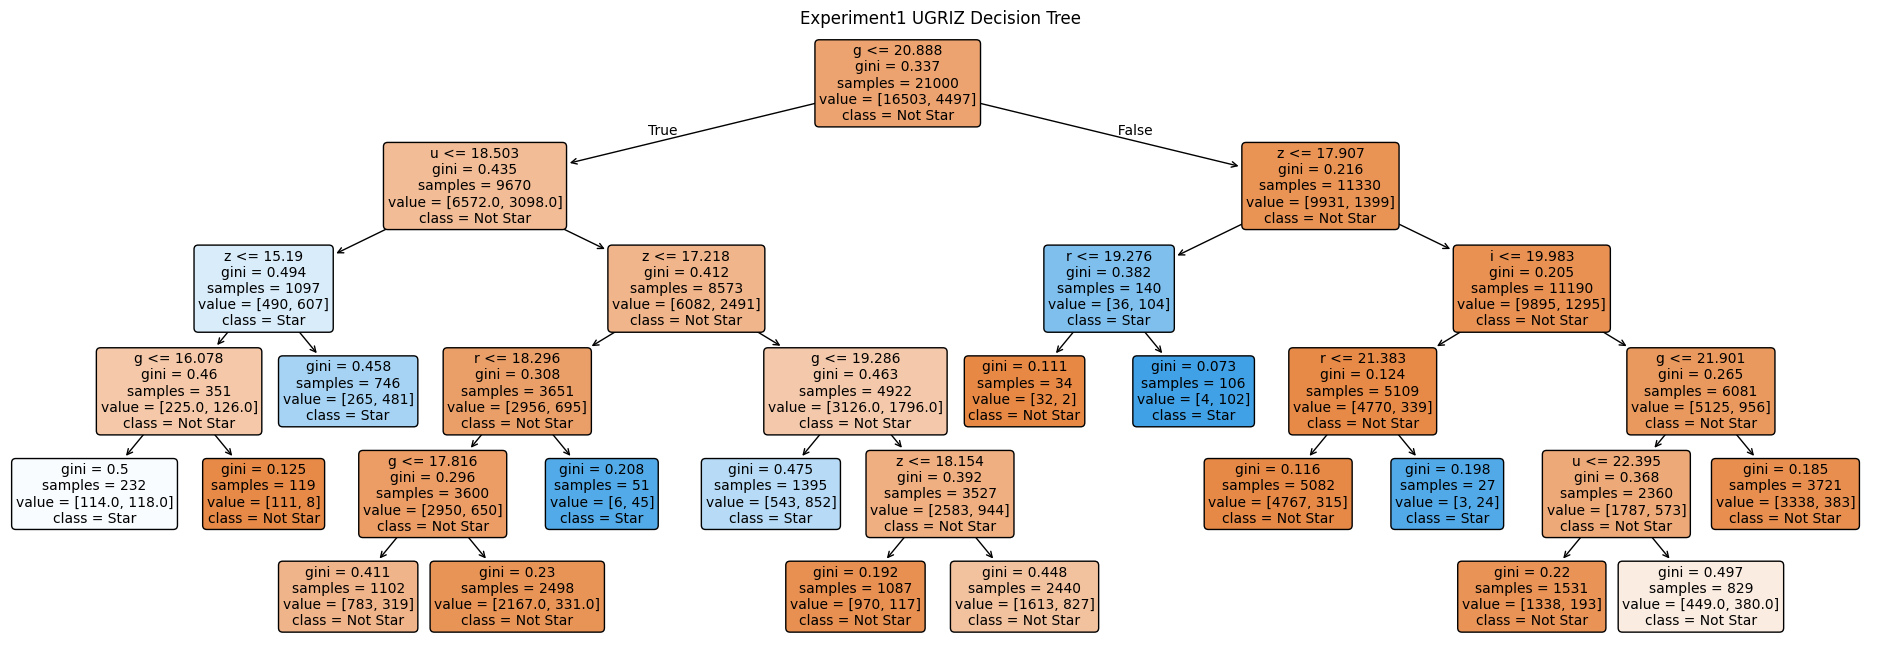

In [ ]:
plt.figure(figsize=(24, 8))
sklearn.tree.plot_tree(
    exp1_model_ugriz,
    feature_names=["u","g","r","i","z"],
    class_names=["Not Star","Star"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Experiment1 UGRIZ Decision Tree")
plt.show()

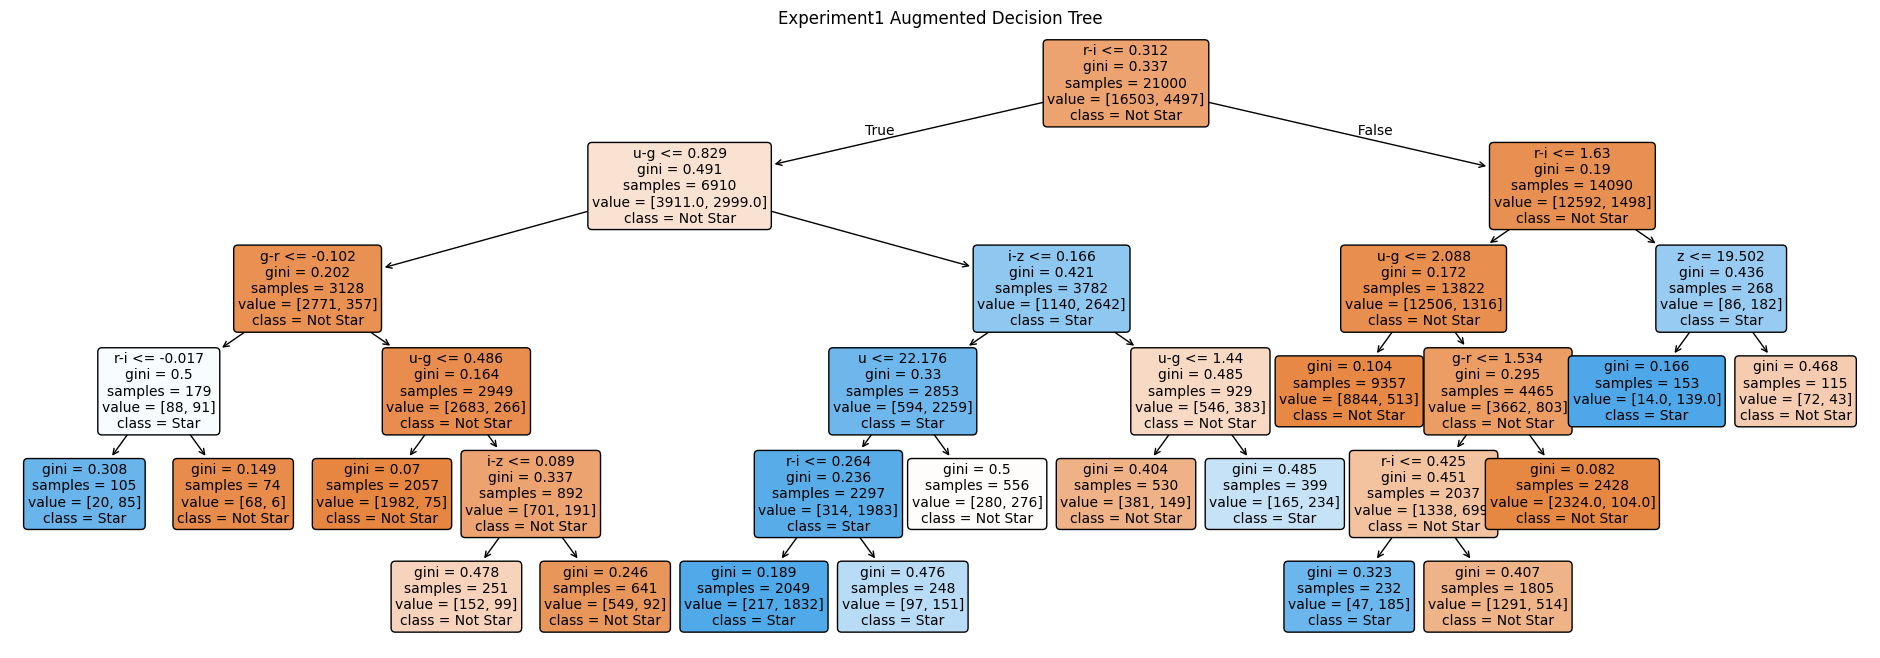

In [ ]:
plt.figure(figsize=(24, 8))
sklearn.tree.plot_tree(
    exp1_model_augmented,
    feature_names=["u","g","r","i","z","u-g","g-r","r-i","i-z"],
    class_names=["Not Star","Star"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Experiment1 Augmented Decision Tree")
plt.show()

### Feature Importance & Tree Structure Analysis
Inspecting the plotted Decision Trees reveals a striking structural pattern: out of **15 total internal splits** in the augmented Decision Tree, **13 splits utilize the band-difference features (`u-g, g-r, r-i, i-z`)** rather than raw magnitudes. This indicates that color differences yield significantly higher Gini impurity reduction, confirming that stars and non-stars are much better separated along distance-invariant color axes.

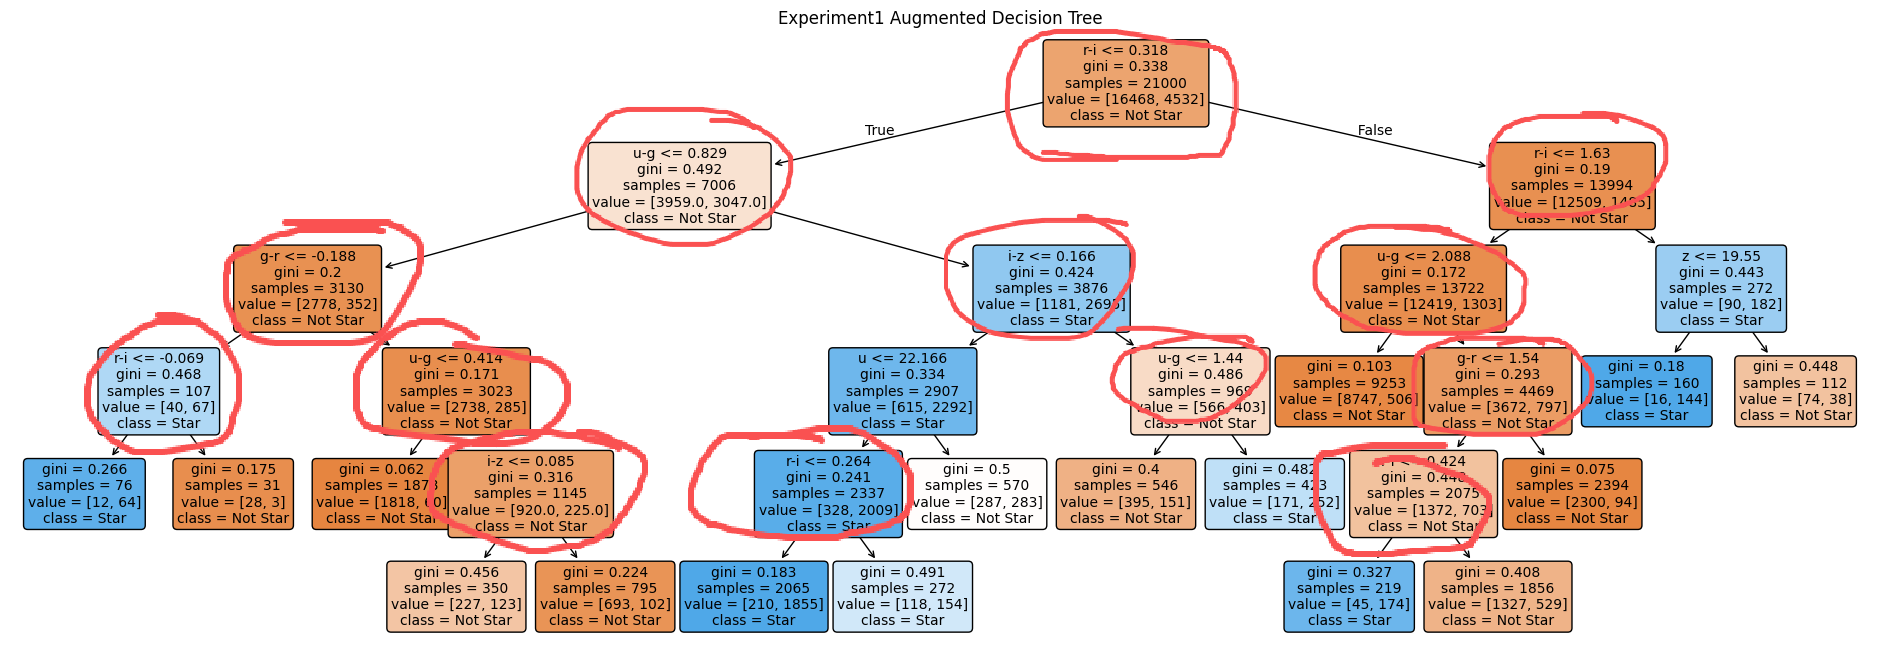

This figure illustrates that most of the splits are splitted based on the difference of filter values(circled in red).

### Conclusion on Experiment 1
**Hypothesis 1 is supported.** Adjacent filter differences capture distance-invariant spectral properties [2] that enable shallow Decision Trees to classify stars far more accurately than raw `UGRIZ` readings alone.

---
## Experiment 2: Intrinsic Dimensionality and Correlation of SDSS Features

### Hypothesis 2
**The SDSS photometric (`UGRIZ`) and astrometric feature columns are strongly correlated, causing the feature matrix to reside on a low-dimensional manifold (approximately rank-deficient).**

* **Physical & Statistical Motivation:** In astrophysics, a star's broadband spectrum is governed by a small number of underlying physical parameters (effective temperature, surface gravity, and metallicity). Consequently, the five `UGRIZ` magnitudes [1] cannot vary independently. In machine learning terms, real-world physical measurements often exhibit strong collinearity, meaning most variance is concentrated in a low-dimensional subspace.

### Experimental Setup
We use 30% of the cleaned dataset (100% fitted for unsupervised variance analysis) and conduct two sets of Principal Component Analysis (PCA) after `StandardScaler` normalization:
1. **8-Feature PCA (`alpha, delta, u, g, r, i, z, redshift`):** Fitted separately on `GALAXY`, `STAR`, and `QSO` subsets to evaluate cumulative Explained Variance Ratio (EVR), plus a unified PCA fitted on all classes combined to visualize 2D and 3D class separability in a shared coordinate system.
2. **5-Feature Photometric PCA (`u, g, r, i, z`):** Fitted separately on `GALAXY`, `STAR`, and `QSO` to isolate collinearity strictly within the optical filter bands.


In [ ]:
#Experiment 2

exp2_data = data.sample(frac=0.3, random_state=RANDOM_SEED, ignore_index=True)

exp2_galaxy_data = exp2_data.loc[exp2_data["class"] == "GALAXY"]
exp2_star_data = exp2_data.loc[exp2_data["class"] == "STAR"]
exp2_quasar_data = exp2_data.loc[exp2_data["class"] == "QSO"]


exp2_X_galaxy = exp2_galaxy_data[["alpha","delta","u","g","r","i","z","redshift"]].to_numpy()
exp2_X_star = exp2_star_data[["alpha","delta","u","g","r","i","z","redshift"]].to_numpy()
exp2_X_quasar = exp2_quasar_data[["alpha","delta","u","g","r","i","z","redshift"]].to_numpy()
exp2_X_all = exp2_data[["alpha","delta","u","g","r","i","z","redshift"]].to_numpy()

exp2_standardizer_galaxy = sklearn.preprocessing.StandardScaler().fit(exp2_X_galaxy)
exp2_standardizer_star = sklearn.preprocessing.StandardScaler().fit(exp2_X_star)
exp2_standardizer_quasar = sklearn.preprocessing.StandardScaler().fit(exp2_X_quasar)
exp2_standardizer_all = sklearn.preprocessing.StandardScaler().fit(exp2_X_all)

exp2_X_std_galaxy = exp2_standardizer_galaxy.transform(exp2_X_galaxy)
exp2_X_std_star = exp2_standardizer_star.transform(exp2_X_star)
exp2_X_std_quasar = exp2_standardizer_quasar.transform(exp2_X_quasar)
exp2_X_std_all = exp2_standardizer_all.transform(exp2_X_all)

exp2_pca8_galaxy = sklearn.decomposition.PCA(n_components=8).fit(exp2_X_std_galaxy)
exp2_pca8_star = sklearn.decomposition.PCA(n_components=8).fit(exp2_X_std_star)
exp2_pca8_quasar = sklearn.decomposition.PCA(n_components=8).fit(exp2_X_std_quasar)
exp2_pca8_all = sklearn.decomposition.PCA(n_components=8).fit(exp2_X_std_all)

In [ ]:
def exp2_plot_evr(components,pca,name):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

  bars1 = ax1.bar(components, pca.explained_variance_ratio_, color='skyblue', edgecolor='black', alpha=0.8)
  ax1.set_xlabel('PCA Component (Dimension)', fontsize=12)
  ax1.set_ylabel('Explained Variance Ratio', fontsize=12)
  ax1.set_title('Explained Variance Ratio per PCA Component ' + name, fontsize=14, fontweight='bold')
  ax1.set_xticks(components)
  ax1.grid(axis='y', linestyle='--', alpha=0.7)

  for bar in bars1:
      yval = bar.get_height()
      ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f'{yval:.2f}',
              ha='center', va='bottom', fontsize=10)

  bars2 = ax2.bar(components, np.cumsum(pca.explained_variance_ratio_), color='salmon', edgecolor='black', alpha=0.8)
  ax2.set_xlabel('Number of PCA Components ', fontsize=12)
  ax2.set_ylabel('Cumulative Explained Variance Ratio', fontsize=12)
  ax2.set_title('Cumulative Explained Variance Ratio ' + name, fontsize=14, fontweight='bold')
  ax2.set_xticks(components)
  ax2.set_ylim(0, 1.05)
  ax2.grid(axis='y', linestyle='--', alpha=0.7)

  ax2.axhline(y=0.95, color='red', linestyle='--', linewidth=2, label='95% Threshold')
  ax2.legend(loc='lower right', fontsize=11)

  for bar in bars2:
      yval = bar.get_height()
      ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.2f}',
              ha='center', va='bottom', fontsize=10)

  plt.tight_layout()
  plt.show()

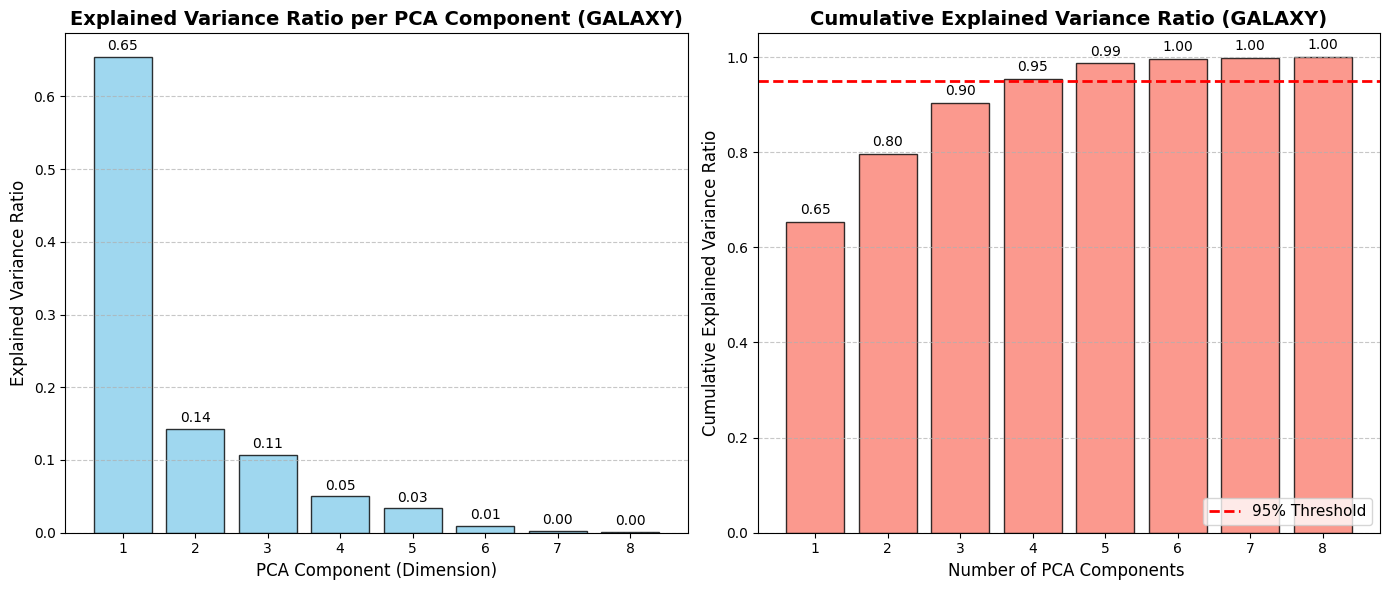

In [ ]:
components = [1,2,3,4,5,6,7,8]
exp2_plot_evr(components,exp2_pca8_galaxy,"(GALAXY)")

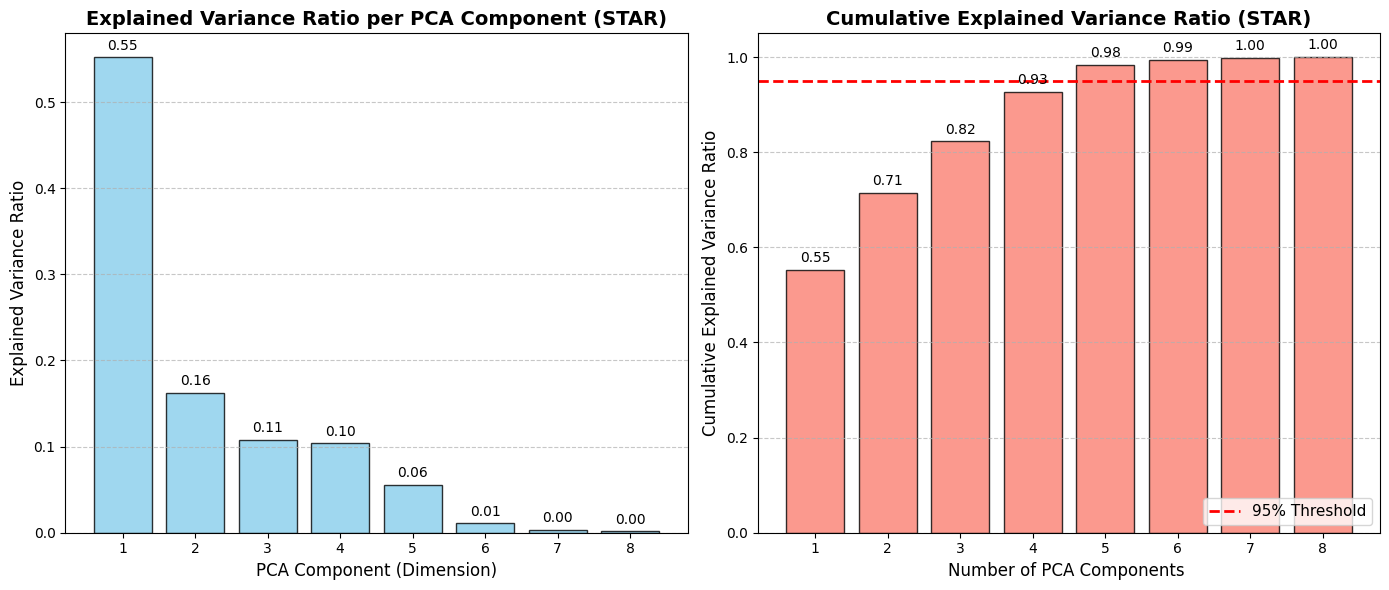

In [ ]:
exp2_plot_evr(components,exp2_pca8_star,"(STAR)")

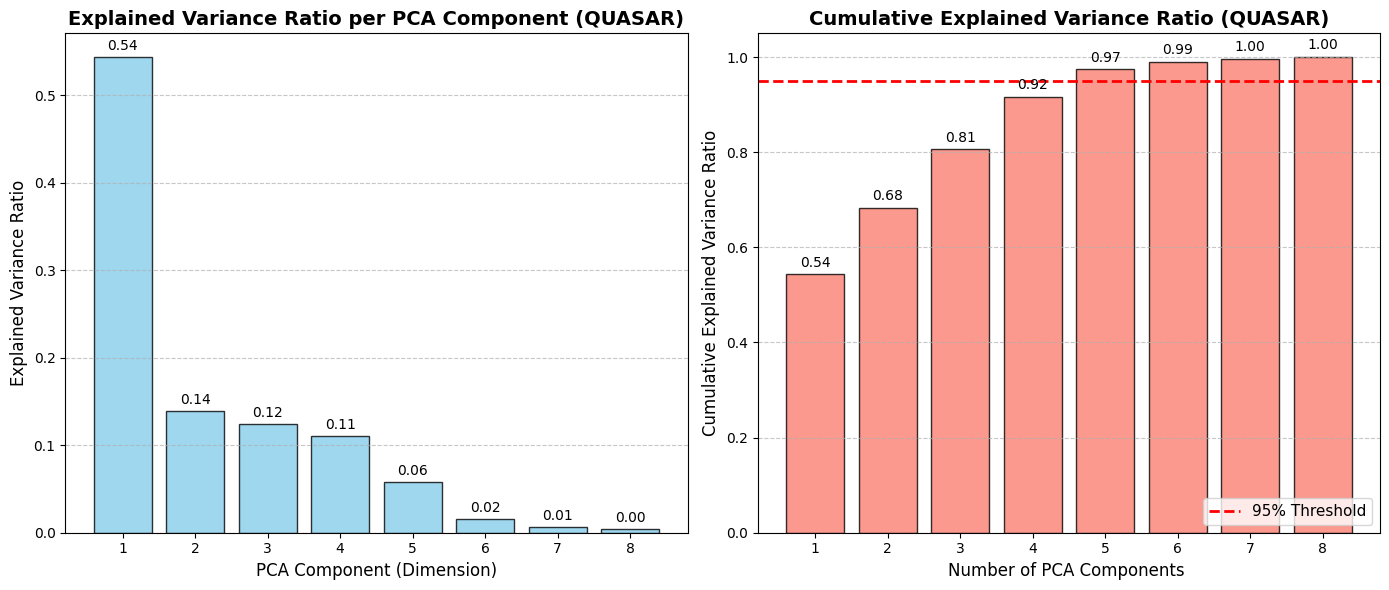

In [ ]:
exp2_plot_evr(components,exp2_pca8_quasar,"(QUASAR)")

In [ ]:
exp2_X_std_projected_galaxy = exp2_pca8_all.transform(exp2_standardizer_all.transform(exp2_X_galaxy))
exp2_X_std_projected_star = exp2_pca8_all.transform(exp2_standardizer_all.transform(exp2_X_star))
exp2_X_std_projected_quasar = exp2_pca8_all.transform(exp2_standardizer_all.transform(exp2_X_quasar))

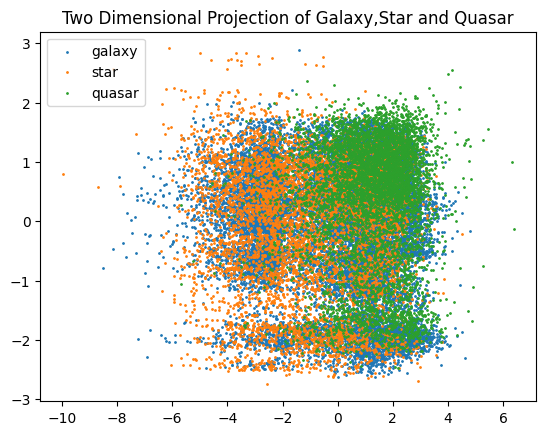

In [ ]:
plt.scatter(exp2_X_std_projected_galaxy[:,0],exp2_X_std_projected_galaxy[:,1],s=1,label="galaxy")
plt.scatter(exp2_X_std_projected_star[:,0],exp2_X_std_projected_star[:,1],s=1,label="star")
plt.scatter(exp2_X_std_projected_quasar[:,0],exp2_X_std_projected_quasar[:,1],s=1,label="quasar")
plt.legend()
plt.title("Two Dimensional Projection of Galaxy,Star and Quasar")
plt.show()

In [ ]:
s1 = go.Scatter3d(
    x=exp2_X_std_projected_galaxy[::3, 0],
    y=exp2_X_std_projected_galaxy[::3, 1],
    z=exp2_X_std_projected_galaxy[::3, 2],
    mode='markers',
    name='galaxy',
    marker=dict(
        size=1,
        opacity=0.8
    )
)

s2 = go.Scatter3d(
    x=exp2_X_std_projected_star[::3, 0],
    y=exp2_X_std_projected_star[::3, 1],
    z=exp2_X_std_projected_star[::3, 2],
    mode='markers',
    name='star',
    marker=dict(
        size=1,
        opacity=0.8
    )
)

s3 = go.Scatter3d(
    x=exp2_X_std_projected_quasar[::3, 0],
    y=exp2_X_std_projected_quasar[::3, 1],
    z=exp2_X_std_projected_quasar[::3, 2],
    mode='markers',
    name='quasar',
    marker=dict(
        size=1,
        opacity=0.8
    )
)

fig = go.Figure(data=[s1, s2, s3])

fig.update_layout(
    title='Three Dimensional Projection of Galaxy,Star and Quasar',
    legend_title_text='Class',
    margin=dict(l=0, r=0, b=0, t=40),
    scene=dict(
        xaxis_title='Component 1',
        yaxis_title='Component 2',
        zaxis_title='Component 3'
    )
)

### Evaluation of 8-Feature PCA & Class Projections
* **Low-Dimensional Subspace:** Across all three celestial classes, the cumulative explained variance ratio exceeds **90% with 4 principal components** and surpasses **95% with 5 components**, confirming that the 8-dimensional feature space is highly redundant and concentrated in a lower-dimensional subspace.
* **Non-Linear Class Boundaries:** Projecting all three classes onto the shared 2D and 3D principal component spaces reveals that `GALAXY`, `STAR`, and `QSO` populations overlap along curved, non-linear manifolds rather than linearly separable hyperplanes. Thus, effective classification without redshift requires non-linear models (such as neural networks) or engineered color features.


In [ ]:
exp2_galaxy_data = exp2_data.loc[exp2_data["class"] == "GALAXY"]
exp2_star_data = exp2_data.loc[exp2_data["class"] == "STAR"]
exp2_quasar_data = exp2_data.loc[exp2_data["class"] == "QSO"]

exp2_X_galaxy = exp2_galaxy_data[["u","g","r","i","z"]].to_numpy()
exp2_X_star = exp2_star_data[["u","g","r","i","z"]].to_numpy()
exp2_X_quasar = exp2_quasar_data[["u","g","r","i","z"]].to_numpy()
exp2_X_all = exp2_data[["u","g","r","i","z"]].to_numpy()

exp2_standardizer_galaxy = sklearn.preprocessing.StandardScaler().fit(exp2_X_galaxy)
exp2_standardizer_star = sklearn.preprocessing.StandardScaler().fit(exp2_X_star)
exp2_standardizer_quasar = sklearn.preprocessing.StandardScaler().fit(exp2_X_quasar)
exp2_standardizer_all = sklearn.preprocessing.StandardScaler().fit(exp2_X_all)

exp2_X_std_galaxy = exp2_standardizer_galaxy.transform(exp2_X_galaxy)
exp2_X_std_star = exp2_standardizer_star.transform(exp2_X_star)
exp2_X_std_quasar = exp2_standardizer_quasar.transform(exp2_X_quasar)
exp2_X_std_all = exp2_standardizer_all.transform(exp2_X_all)

exp2_pca5_galaxy = sklearn.decomposition.PCA(n_components=5).fit(exp2_X_std_galaxy)
exp2_pca5_star = sklearn.decomposition.PCA(n_components=5).fit(exp2_X_std_star)
exp2_pca5_quasar = sklearn.decomposition.PCA(n_components=5).fit(exp2_X_std_quasar)
exp2_pca5_all = sklearn.decomposition.PCA(n_components=5).fit(exp2_X_std_all)

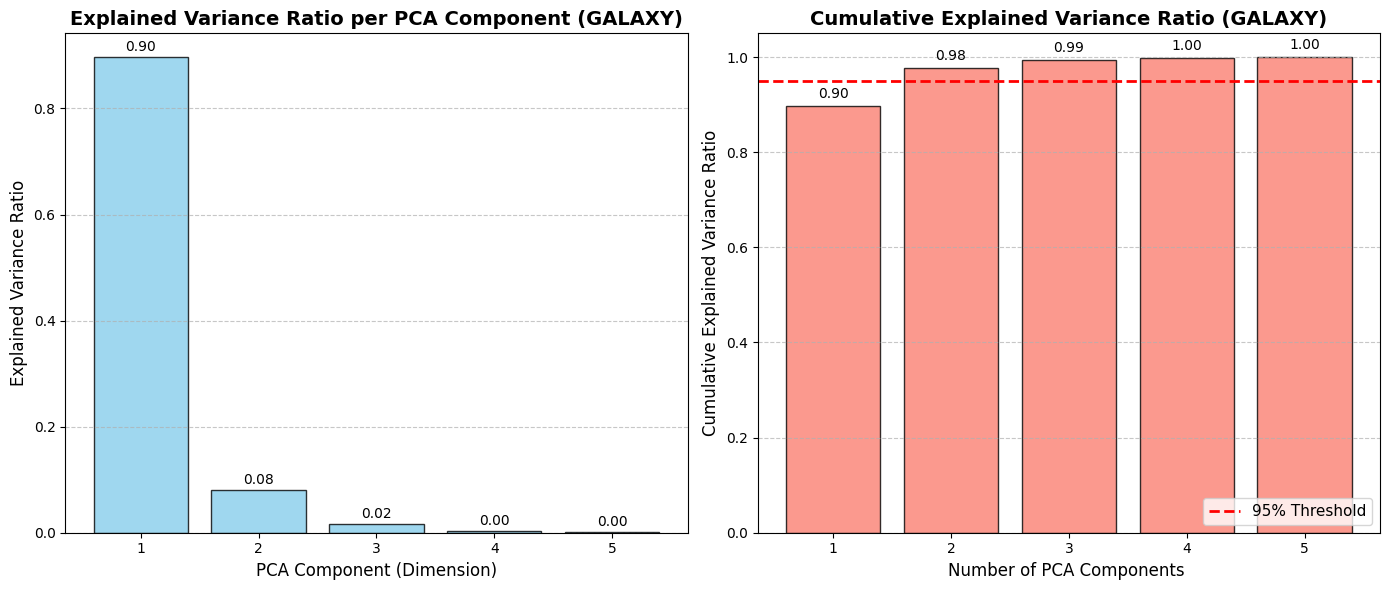

In [ ]:
components = [1,2,3,4,5]
exp2_plot_evr(components,exp2_pca5_galaxy,"(GALAXY)")

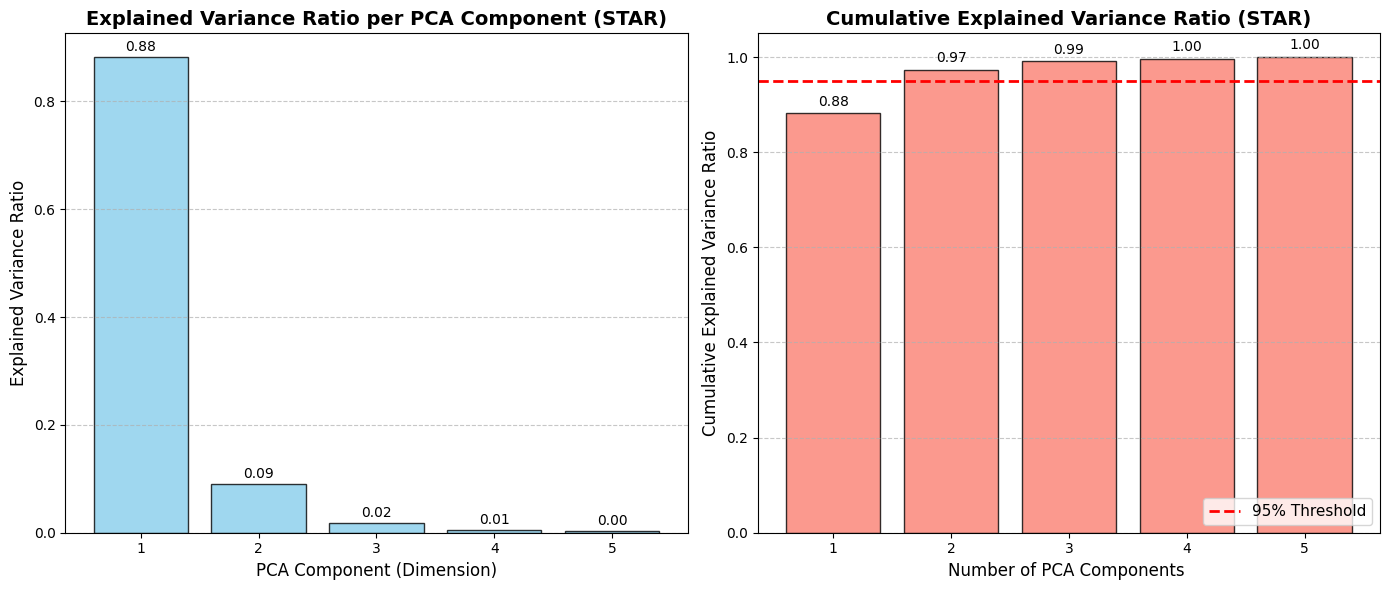

In [ ]:
exp2_plot_evr(components,exp2_pca5_star,"(STAR)")

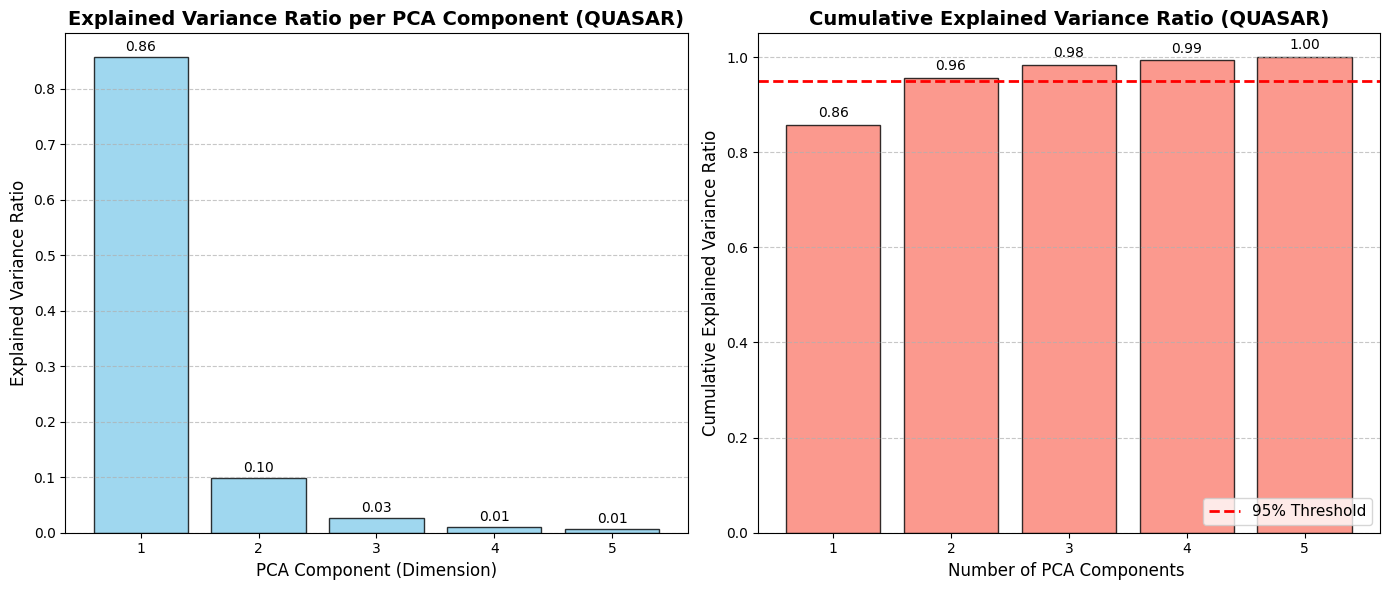

In [ ]:
exp2_plot_evr(components,exp2_pca5_quasar,"(QUASAR)")

In [ ]:
print("First component of galaxy PCA ",exp2_pca5_galaxy.components_[0])
print("First component of star PCA ",exp2_pca5_star.components_[0])
print("First component of quasar PCA ",exp2_pca5_quasar.components_[0])

First component of galaxy PCA  [0.39734456 0.45824631 0.46616252 0.46066835 0.45011643]
First component of star PCA  [0.41837753 0.4565102  0.46911262 0.45756847 0.4325773 ]
First component of quasar PCA  [0.39848166 0.45828366 0.47082865 0.46243871 0.44233389]


In [ ]:
print("Second component of galaxy PCA ",exp2_pca5_galaxy.components_[1])
print("Second component of star PCA ",exp2_pca5_star.components_[1])
print("Second component of quasar PCA ",exp2_pca5_quasar.components_[1])

Second component of galaxy PCA  [ 0.83452932  0.14675127 -0.16432805 -0.30995122 -0.39868711]
Second component of star PCA  [ 0.65604139  0.33415489 -0.02806814 -0.36856242 -0.56685459]
Second component of quasar PCA  [ 0.75883958  0.25858774 -0.11100897 -0.33700187 -0.48104222]


### Evaluation of 5-Feature Photometric (`UGRIZ`) PCA
* **Two-Dimensional Optical Manifold:** When restricting PCA exclusively to the five `UGRIZ` bands, **just 2 principal components capture over 95% of the total variance** across all three celestial types. The first principal component (`PC1`) exhibits nearly uniform positive weights across all five bands (representing overall apparent brightness/distance), while the second component (`PC2`) contrasts short wavelengths (`u, g`) against long wavelengths (`i, z`), corresponding directly to the spectral color slope explored in Experiment 1.
* **Higher Complexity in Quasars:** Notably, `PC1` and `PC2` explain a slightly smaller fraction of variance for `QSO` compared to `GALAXY` and `STAR`, and the cumulative variance rises more gradually. This reflects the diverse emission lines and wide redshift range of quasars, motivating our deep learning investigation in Experiment 3.

### Conclusion on Experiment 2
**Hypothesis 2 is supported.** The `UGRIZ` photometric matrix feature vectors effectively spans a 2D subspace governed by overall brightness and spectral color slope, while class boundaries between stars, galaxies, and quasars remain non-linear.

---
## Experiment 3: Non-Linear Quasar Classification Without Redshift via Neural Networks

### Hypothesis 3
**Non-linear patterns within SDSS `UGRIZ` magnitudes and their pairwise differences enable a Multi-Layer Perceptron (MLP) to effectively classify quasars without spectroscopic redshift, including challenging high-redshift quasars ($5 < z < 6$).**

* **Astrophysical Motivation:** Photometric quasar selection is a classic challenge in observational astronomy. As documented by Richards et al.[3], traditional linear color-cut algorithms often miss quasars around $z \sim 5$. At this redshift, neutral hydrogen along the line of sight absorbs flux blueward of the Lyman-$\alpha$ emission line (the Lyman-$\alpha$ break), causing severe flux dropout in the `u, g, r` bands and creating a strong **optical color degeneracy** with cool galactic M-dwarf stars. Furthermore, both quasars and stars appear as unresolved point sources. While previous works recover these "redshift-gap" quasars by adding near- or mid-infrared surveys[4], we test whether a non-linear neural network can learn subtle decision boundaries from optical `UGRIZ` photometry alone.

### Model Formulation & Training Setup
* **Task & Data Split:** Binary classification (`1` = `QSO`, `0` = `GALAXY` or `STAR`). The cleaned dataset is randomly shuffled and split into **70% training, 20% validation, and 10% testing**.
* **Input Features (9D):** Standardized `u, g, r, i, z` magnitudes [1] combined with the 4 adjacent color differences (`u-g, g-r, r-i, i-z`) validated in Experiment 1.
* **Network Architecture:** A fully connected MLP with 3 hidden layers (`9 -> 32 -> 64 -> 128`), `SiLU` activations, and a `BatchNorm1d(128)` layer prior to the final linear output (`128 -> 1`). Including `BatchNorm1d` stabilizes gradient flow across skewed astrophysical magnitude distributions and prevents the network from collapsing into trivial all-negative predictions under class imbalance.
* **Optimization & Hyperparameter Selection:** Trained for 100 epochs using `BCEWithLogitsLoss` and the **AdamW** optimizer (`lr=0.001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0.01`). Learning rate tuning showed that an overly large step size (`lr=0.1`) caused activation saturation, whereas `lr=0.001` paired with feature standardization achieved smooth convergence. The checkpoint achieving the lowest validation loss is retained for final testing.


In [ ]:
#Experiment 3
device = "cuda" if torch.cuda.is_available() else "cpu"

exp3_data = data.sample(frac=1, random_state=RANDOM_SEED, ignore_index=True)

exp3_label = exp3_data["class"].map({"QSO":1,"GALAXY":0,"STAR":0}).to_numpy()
exp3_X = exp3_data[["u","g","r","i","z"]].to_numpy()
exp3_X = np.concat((exp3_X,exp3_X[:,:-1]-exp3_X[:,1:]),axis=1)

TRAIN_INDEX = (int)(0.7 * len(exp3_X))
VALID_LEN = (int)(0.2 * len(exp3_X))
exp3_X_train = exp3_X[:TRAIN_INDEX]
exp3_X_valid = exp3_X[TRAIN_INDEX:TRAIN_INDEX+VALID_LEN]
exp3_X_test = exp3_X[TRAIN_INDEX+VALID_LEN:]
exp3_y_train = exp3_label[:TRAIN_INDEX]
exp3_y_valid = exp3_label[TRAIN_INDEX:TRAIN_INDEX+VALID_LEN]
exp3_y_test = exp3_label[TRAIN_INDEX+VALID_LEN:]

In [ ]:
exp3_X_standardizer = sklearn.preprocessing.StandardScaler().fit(exp3_X_train)
exp3_X_std_train = exp3_X_standardizer.transform(exp3_X_train)
exp3_X_std_valid = exp3_X_standardizer.transform(exp3_X_valid)
exp3_X_std_test = exp3_X_standardizer.transform(exp3_X_test)

exp3_train_set = torch.utils.data.TensorDataset(torch.tensor(exp3_X_std_train,dtype=torch.float32),torch.tensor(exp3_y_train,dtype=torch.float32).reshape(-1,1))
exp3_valid_set = torch.utils.data.TensorDataset(torch.tensor(exp3_X_std_valid,dtype=torch.float32),torch.tensor(exp3_y_valid,dtype=torch.float32).reshape(-1,1))
exp3_test_set = torch.utils.data.TensorDataset(torch.tensor(exp3_X_std_test,dtype=torch.float32),torch.tensor(exp3_y_test,dtype=torch.float32).reshape(-1,1))

g = torch.Generator()
g.manual_seed(RANDOM_SEED)
exp3_train_dataloader = torch.utils.data.DataLoader(exp3_train_set,batch_size=128,shuffle=True,num_workers=2,generator=g)
exp3_valid_dataloader = torch.utils.data.DataLoader(exp3_valid_set,batch_size=128,shuffle=False,num_workers=2,generator=g)
exp3_test_dataloader = torch.utils.data.DataLoader(exp3_test_set,batch_size=128,shuffle=False,num_workers=2,generator=g)

exp3_nn = nn.Sequential(
    nn.Linear(9,32),
    nn.SiLU(),
    nn.Linear(32,64),
    nn.SiLU(),
    nn.Linear(64,128),
    nn.SiLU(),
    nn.BatchNorm1d(128),
    nn.SiLU(),
    nn.Linear(128,1)
).to(device)

exp3_nn_optimizer = torch.optim.AdamW(exp3_nn.parameters(),lr=0.001,betas=(0.9, 0.999),eps=1e-08,weight_decay=0.01,amsgrad=False,fused=torch.cuda.is_available())

### Training & Validation Protocol
To optimize computational efficiency on CPU/GPU, the training loss reported at each epoch is the accumulated mini-batch binary cross-entropy loss (`batch_size=128`), while validation loss is evaluated across the full held-out validation set (`VALID_LEN`) in evaluation mode (`model.eval()`). We perform deep-copy checkpointing (`copy.deepcopy`) whenever validation loss reaches a new minimum to prevent overfitting before evaluating on the unseen test set.


In [ ]:
exp3_epoch = 100
exp3_train_criterion = nn.BCEWithLogitsLoss()
exp3_valid_criterion = nn.BCEWithLogitsLoss(reduction="sum")

training_history = []
best_score = torch.inf
best_model = None
for e in range(exp3_epoch):
  exp3_nn.train()
  cum_loss = 0
  for X,y in exp3_train_dataloader:
    X = X.to(device)
    y = y.to(device)
    exp3_nn_optimizer.zero_grad()
    y_pred = exp3_nn(X)
    loss = exp3_train_criterion(y_pred,y)
    loss.backward()
    exp3_nn_optimizer.step()
    cum_loss += loss.item()

  print("The cumulated training loss in training for epoch ",e," is ",cum_loss)

  exp3_nn.eval()
  with torch.no_grad():
    valid_loss = 0
    for X,y in exp3_valid_dataloader:
      X = X.to(device)
      y = y.to(device).reshape(-1,1)
      y_pred = exp3_nn(X)
      valid_loss += exp3_valid_criterion(y_pred,y).item()

  valid_loss /= VALID_LEN
  print("The validation loss in training for epoch ",e," is ",valid_loss)
  if valid_loss < best_score:
    best_model = copy.deepcopy(exp3_nn.state_dict())
    best_score = valid_loss

  training_history.append((cum_loss,valid_loss))

print("-----Training Terminated-----")

checkpoint = {
    "model_state_dict": best_model,
    "scaler_mean": exp3_X_standardizer.mean_,
    "scaler_scale": exp3_X_standardizer.scale_,
    "best_valid_loss": best_score
}

save_path = "sdss_quasar_mlp_best.pth"
torch.save(checkpoint, save_path)
print(f"Successfully saved model weights to {save_path}")

The cumulated training loss in training for epoch  0  is  125.99095776677132
The validation loss in training for epoch  0  is  0.20772385782012642
The cumulated training loss in training for epoch  1  is  109.1675184816122
The validation loss in training for epoch  1  is  0.20232103090178008
The cumulated training loss in training for epoch  2  is  106.27183470875025
The validation loss in training for epoch  2  is  0.1954322454720606
The cumulated training loss in training for epoch  3  is  104.82195539027452
The validation loss in training for epoch  3  is  0.18959471616597645
The cumulated training loss in training for epoch  4  is  103.30456736683846
The validation loss in training for epoch  4  is  0.19015892801704903
The cumulated training loss in training for epoch  5  is  102.63882445544004
The validation loss in training for epoch  5  is  0.18807817345899644
The cumulated training loss in training for epoch  6  is  101.49091117829084
The validation loss in training for epoch  

In [127]:
checkpoint = torch.load("sdss_quasar_mlp_best.pth", map_location=device, weights_only=False)

exp3_nn.load_state_dict(checkpoint["model_state_dict"])
exp3_nn.eval()

exp3_X_standardizer.mean_ = checkpoint["scaler_mean"]
exp3_X_standardizer.scale_ = checkpoint["scaler_scale"]

In [128]:
print("-----Evaluating Final Loss-----")
cum_loss = 0
with torch.no_grad():
  for X,y in exp3_train_dataloader:
    exp3_nn.eval()
    X = X.to(device)
    y = y.to(device).reshape(-1,1)
    y_pred = exp3_nn(X)
    cum_loss += exp3_valid_criterion(y_pred,y).item()

print("The cumulated training loss after training is ",cum_loss / len(exp3_X_train))

cum_loss = 0
with torch.no_grad():
  for X,y in exp3_valid_dataloader:
    exp3_nn.eval()
    X = X.to(device)
    y = y.to(device).reshape(-1,1)
    y_pred = exp3_nn(X)
    cum_loss += exp3_valid_criterion(y_pred,y).item()

print("The cumulated validation loss after training is ",cum_loss / VALID_LEN)

-----Evaluating Final Loss-----
The cumulated training loss after training is  0.1657228074749343
The cumulated validation loss after training is  0.1742565916671688


In [129]:
exp3_nn.load_state_dict(best_model)
exp3_nn.eval()
exp3_y_pred_test = np.zeros(len(exp3_y_test)).reshape(-1,1)
with torch.no_grad():
  exp3_y_pred_score_test = nn.functional.sigmoid(exp3_nn(torch.tensor(exp3_X_std_test,dtype=torch.float32,requires_grad=False))).cpu().detach().numpy()
exp3_y_pred_test[exp3_y_pred_score_test >= 0.5] = 1
exp3_recall_test = sklearn.metrics.recall_score(exp3_y_test,exp3_y_pred_test)
exp3_precision_test = sklearn.metrics.precision_score(exp3_y_test,exp3_y_pred_test)
exp3_confusion_matrix_test = sklearn.metrics.confusion_matrix(exp3_y_test,exp3_y_pred_test)

-----Metrics-----
PRECISION:
The precision of the NN is  0.8097587719298246

RECALL:
The recall of the NN is  0.7975161987041036

CONFUSION MATRIX
The confusion matrix of the NN


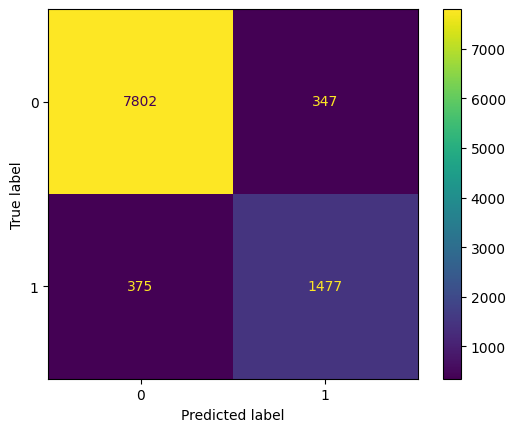

In [130]:
print("-----Metrics-----")
print("PRECISION:")
print("The precision of the NN is ",exp3_precision_test)
print()
print("RECALL:")
print("The recall of the NN is ",exp3_recall_test)
print()
print("CONFUSION MATRIX")
print("The confusion matrix of the NN")
sklearn.metrics.ConfusionMatrixDisplay(exp3_confusion_matrix_test).plot()

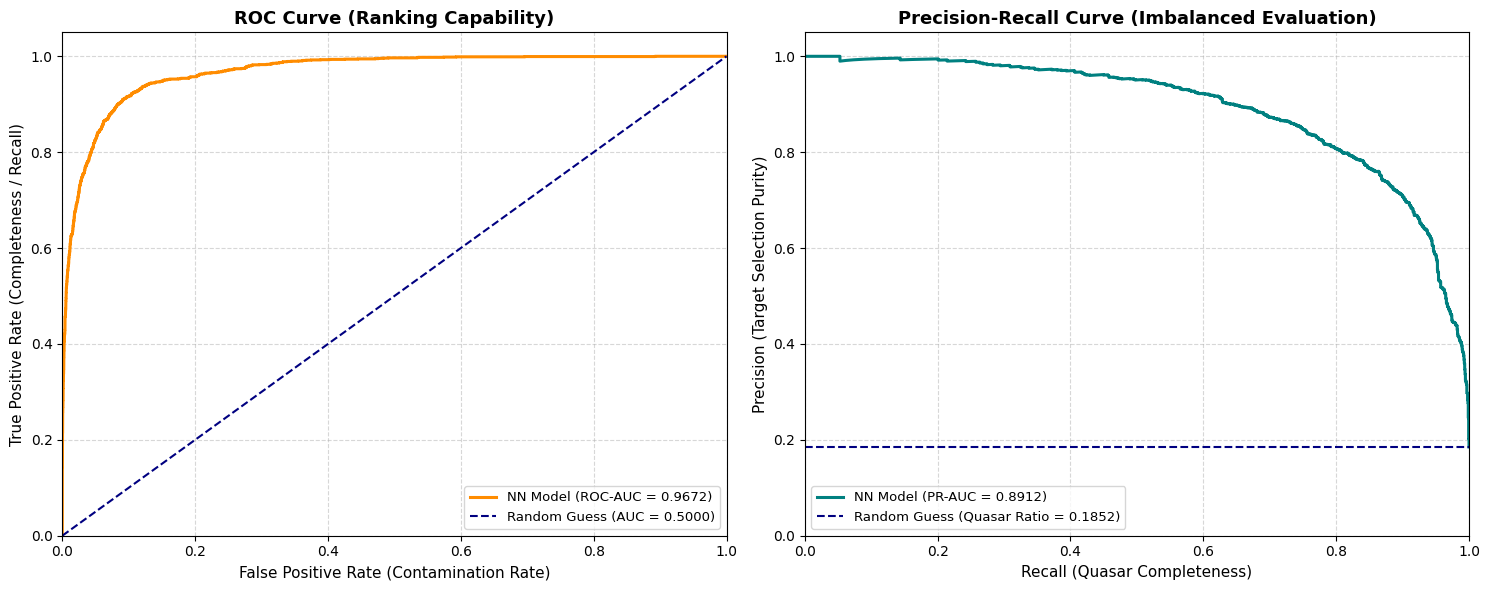

In [ ]:
fpr, tpr, roc_thresholds = sklearn.metrics.roc_curve(exp3_y_test, exp3_y_pred_score_test)
roc_auc = sklearn.metrics.roc_auc_score(exp3_y_test, exp3_y_pred_score_test)

precision, recall, pr_thresholds = sklearn.metrics.precision_recall_curve(exp3_y_test, exp3_y_pred_score_test)
pr_auc = sklearn.metrics.average_precision_score(exp3_y_test, exp3_y_pred_score_test)
baseline_pr = exp3_y_test.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(fpr, tpr, color='darkorange', lw=2.2, label=f'NN Model (ROC-AUC = {roc_auc:.4f})')
ax1.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate (Contamination Rate)', fontsize=11)
ax1.set_ylabel('True Positive Rate (Completeness / Recall)', fontsize=11)
ax1.set_title('ROC Curve (Ranking Capability)', fontsize=13, fontweight='bold')
ax1.legend(loc='lower right', fontsize=9.5)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(recall, precision, color='teal', lw=2.2, label=f'NN Model (PR-AUC = {pr_auc:.4f})')
ax2.axhline(y=baseline_pr, color='navy', lw=1.5, linestyle='--',
            label=f'Random Guess (Quasar Ratio = {baseline_pr:.4f})')

ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall (Quasar Completeness)', fontsize=11)
ax2.set_ylabel('Precision (Target Selection Purity)', fontsize=11)
ax2.set_title('Precision-Recall Curve (Imbalanced Evaluation)', fontsize=13, fontweight='bold')
ax2.legend(loc='lower left', fontsize=9.5)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

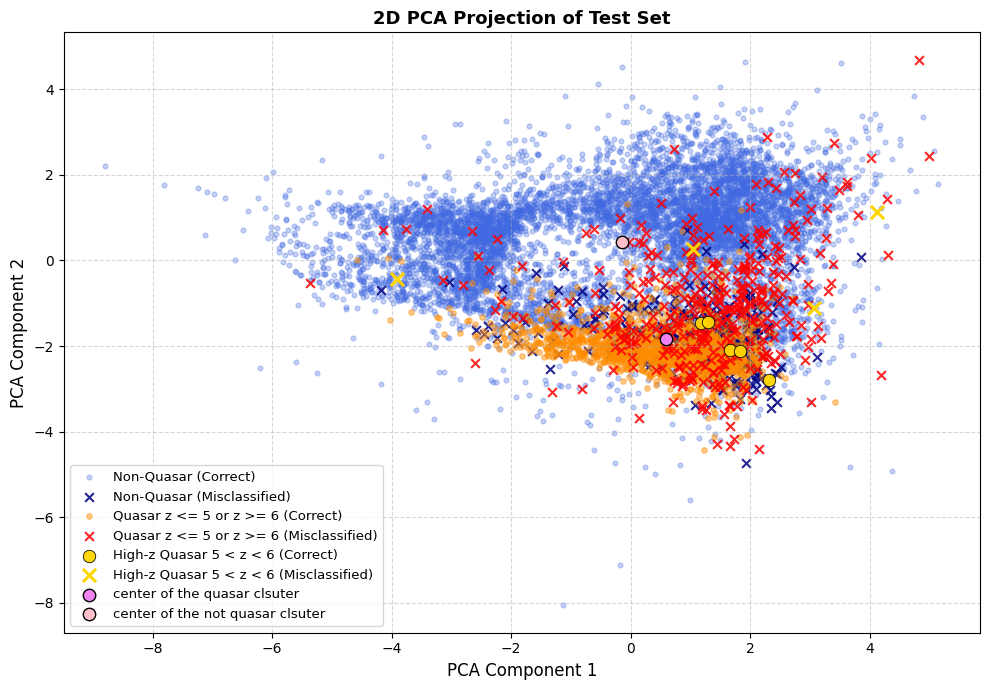

High-z Quasars (5 < z < 6) in Test Set: 5 / 9 correctly classified.


In [116]:
exp3_standardizer = sklearn.preprocessing.StandardScaler().fit(exp3_X)
exp3_redshift_test = exp3_data["redshift"].to_numpy()[TRAIN_INDEX + VALID_LEN:]
exp3_center_quasar = exp3_standardizer.transform(exp3_X_test[exp3_y_test == 1].mean(axis=0).reshape(1,-1))
exp3_center_not_quasar = exp3_standardizer.transform(exp3_X_test[exp3_y_test == 0].mean(axis=0).reshape(1,-1))
exp3_pca = sklearn.decomposition.PCA().fit(exp3_standardizer.transform(exp3_X))

test_pca_2d = exp3_pca.transform(exp3_standardizer.transform(exp3_X_test))[:, :2]
exp3_center_quasar_2d = exp3_pca.transform(exp3_center_quasar)[:,:2].flatten()
exp3_center_not_quasar_2d = exp3_pca.transform(exp3_center_not_quasar)[:,:2].flatten()

y_true = exp3_y_test.flatten()
y_pred = exp3_y_pred_test.flatten()

high_z_mask = (y_true == 1) & (exp3_redshift_test > 5) & (exp3_redshift_test < 6)
normal_qso_mask = (y_true == 1) & (~high_z_mask)
non_qso_mask = (y_true == 0)

correct_mask = (y_true == y_pred)
mis_mask = (y_true != y_pred)

plt.figure(figsize=(10, 7))

plt.scatter(test_pca_2d[non_qso_mask & correct_mask, 0], test_pca_2d[non_qso_mask & correct_mask, 1],
            c='royalblue', marker='o', s=12, alpha=0.3, label='Non-Quasar (Correct)')
plt.scatter(test_pca_2d[non_qso_mask & mis_mask, 0], test_pca_2d[non_qso_mask & mis_mask, 1],
            c='navy', marker='x', s=40, linewidths=1.5, alpha=0.85, label='Non-Quasar (Misclassified)')

plt.scatter(test_pca_2d[normal_qso_mask & correct_mask, 0], test_pca_2d[normal_qso_mask & correct_mask, 1],
            c='darkorange', marker='o', s=15, alpha=0.45, label='Quasar z <= 5 or z >= 6 (Correct)')
plt.scatter(test_pca_2d[normal_qso_mask & mis_mask, 0], test_pca_2d[normal_qso_mask & mis_mask, 1],
            c='red', marker='x', s=40, linewidths=1.5, alpha=0.85, label='Quasar z <= 5 or z >= 6 (Misclassified)')

plt.scatter(test_pca_2d[high_z_mask & correct_mask, 0], test_pca_2d[high_z_mask & correct_mask, 1],
            c='gold', edgecolors='black', linewidths=0.6, marker='o', s=80, alpha=0.95,
            label='High-z Quasar 5 < z < 6 (Correct)', zorder=5)
plt.scatter(test_pca_2d[high_z_mask & mis_mask, 0], test_pca_2d[high_z_mask & mis_mask, 1],
            c='gold', marker='x', s=90, linewidths=2.2, alpha=1.0,
            label='High-z Quasar 5 < z < 6 (Misclassified)', zorder=6)

plt.scatter(exp3_center_quasar_2d[0],exp3_center_quasar_2d[1],c="violet",edgecolors="black",s=80,label="center of the quasar clsuter")
plt.scatter(exp3_center_not_quasar_2d[0],exp3_center_not_quasar_2d[1],c="pink",edgecolors="black",s=80,label="center of the not quasar clsuter")

plt.xlabel('PCA Component 1', fontsize=12)
plt.ylabel('PCA Component 2', fontsize=12)
plt.title('2D PCA Projection of Test Set', fontsize=13, fontweight='bold')
plt.legend(loc='best', fontsize=9.5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

total_hz = high_z_mask.sum()
correct_hz = (high_z_mask & correct_mask).sum()
print(f"High-z Quasars (5 < z < 6) in Test Set: {correct_hz} / {total_hz} correctly classified.")


In [126]:
print("The euclidean distance space from the correctly classified samples to the cluster of quasars and the cluster of not quasars are")
correct = exp3_standardizer.transform(exp3_X_test[high_z_mask & correct_mask])
distance_quasar = correct - exp3_center_quasar
distance_not_quasar = correct - exp3_center_not_quasar
for i in range(len(distance_quasar)):
  u = np.linalg.norm(distance_quasar[i])
  v = np.linalg.norm(distance_not_quasar[i])
  print(u,v,";this sample is classified as ",1 if u < v else 0)

print("With average distances ", np.linalg.norm(distance_quasar,axis=1).mean(axis=0),np.linalg.norm(distance_not_quasar,axis=1).mean(axis=0))
print("----------")
print("The euclidean distance from the missclassified samples to the cluster of quasars and the cluster of not quasars are")
incorrect = exp3_standardizer.transform(exp3_X_test[high_z_mask & ~correct_mask])
distance_quasar = incorrect - exp3_center_quasar
distance_not_quasar = incorrect - exp3_center_not_quasar
for i in range(len(distance_quasar)):
  u = np.linalg.norm(distance_quasar[i])
  v = np.linalg.norm(distance_not_quasar[i])
  print(u,v,";this sample is classified as ",1 if u < v else 0)

print("With average distances ", np.linalg.norm(distance_quasar,axis=1).mean(axis=0),np.linalg.norm(distance_not_quasar,axis=1).mean(axis=0))

The euclidean distance space from the correctly classified samples to the cluster of quasars and the cluster of not quasars are
1.8277945703548746 3.4925201262892664 ;this sample is classified as  1
1.803059505815598 2.921850296508279 ;this sample is classified as  1
2.952354777694329 4.579002124854497 ;this sample is classified as  1
3.4618058263831 4.578760691979338 ;this sample is classified as  1
1.0812155208515286 2.4351998930397594 ;this sample is classified as  1
With average distances  2.2252460402198864 3.601466626534228
----------
The euclidean distance from the missclassified samples to the cluster of quasars and the cluster of not quasars are
2.6431694478009233 1.8292975138678844 ;this sample is classified as  0
4.742503700474905 3.8660579556575416 ;this sample is classified as  0
2.650095957695797 3.655335393696568 ;this sample is classified as  1
8.003489071793386 7.772270942674927 ;this sample is classified as  0
With average distances  4.5098145444412525 4.2807404514742

### Evaluation & High-Redshift Error Analysis

1. **Strong Global Classification Performance:**  
   On the unseen test set ($N = 10,001$), the neural network achieves **80.98% Precision** (`0.8098`), **79.75% Recall** (`0.7975`), a **ROC-AUC of 0.9672**, and a **PR-AUC of 0.8912** (nearly **4.8× higher** than the random-selection baseline of `0.1852`). As shown in the confusion matrix (`TN = 7,802`, `FP = 347`, `FN = 375`, `TP = 1,477`), the model accurately captures nearly 80% of all true quasars while maintaining over 80% candidate purity without prior spectroscopic redshift measurements. Furthermore, the Precision-Recall curve illustrates an operational "sweet spot" around **80% recall**, beyond which precision drops sharply as the decision threshold enters the stellar contamination regime.

2. **Targeted Slice Analysis on High-Redshift Quasars ($5 < z < 6$):**  
   Focusing on the rare high-redshift subset ($5 < z < 6$)—which corresponds to the critical "redshift gap" highlighted in prior literature [3, 4]—the model correctly identifies **5 out of 9 test quasars (55.56% recall)** and misclassifies **4**. While this substantially improves upon traditional optical color-cut criteria that systematically exclude this gap (~0% recovery), it still trails the model's global recall (79.75%).

3. **Comparison with Nearest-Centroid (K-Means) Clustering & Feature-Space Distance:**  
   To evaluate whether the neural network learns deeper non-linear patterns beyond simple geometric proximity for high-redshift quasars ($5 < z < 6$), we compare the MLP's predictions against a **Nearest-Centroid (K-Means style)** classifier using standardized 9D Euclidean distances to the **Quasar Cluster Center** ($d_{\text{QSO}}$) and **Non-Quasar Cluster Center** ($d_{\text{Non-QSO}}$):
   * **5 Samples Correctly Classified by the NN:** All 5 samples lie substantially closer to the quasar centroid than to the non-quasar centroid (**average $d_{\text{QSO}} = 2.23$** vs. **average $d_{\text{Non-QSO}} = 3.60$**), so Nearest-Centroid clustering also classifies all 5 as quasars (`Class 1`).
   * **4 Samples Misclassified by the NN (Predicted as `0`):** These samples lie much farther from the quasar core (**average $d_{\text{QSO}} = 4.51$** vs. **average $d_{\text{Non-QSO}} = 4.28$**). Nearest-Centroid clustering assigns 3 of them to `Class 0` (closer to the non-quasar M-dwarf manifold) and still recovers 1 boundary sample ($d_{\text{QSO}} = 2.65 < d_{\text{Non-QSO}} = 3.66$) as `Class 1`, achieving **6/9 (66.67%)** recall compared to the NN's **5/9 (55.56%)**.

   **Key Takeaway:** Explicitly contrasting the MLP against Nearest-Centroid clustering confirms that for extreme high-redshift quasars ($5 < z < 6$), the neural network does not outperform simple distance-based clustering. Once redshifted Lyman-$\alpha$ flux dropout shifts a $z \sim 5.5$ quasar away from the dominant low-redshift quasar core into the cool M-dwarf color locus, we can not prove that optical `UGRIZ` photometry alone can provide sufficient spectral contrast for the network to separate them.



### Additional Comments
Two key factors limit high-redshift recall in the current setup:
* **Extreme Sub-Class Scarcity:** Quasars with $5 < z < 6$ account for **less than 0.1%** of the entire SDSS17 dataset (~60 training samples out of 70,000), causing global cross-entropy optimization to prioritize the dominant $z < 4$ population.
* **Optical Wavelength Ceiling:** At $z > 5$, near-total flux absorption in the blue optical bands leaves insufficient spectral contrast between quasars and cool M-dwarfs.

---
## Overall Project Conclusion

In this project, we systematically investigated the SDSS17 photometric dataset across three hypothesis-driven experiments to determine how effectively celestial objects—and specifically quasars—can be classified using optical `UGRIZ` photometry without spectroscopic redshift:

1. **Color Differences Mitigate Distance Effects (Experiment 1):** Supplying adjacent filter differences (`u-g, g-r, r-i, i-z`) substantially reduces Gini impurity and improves Decision Tree precision, recall, and MSE over raw magnitudes alone.
2. **Low-Dimensional Manifold Structure (Experiment 2):** PCA demonstrates that `UGRIZ` photometry is highly collinear, with **2 principal components explaining >95% of variance** (corresponding to overall brightness and spectral color slope), though class boundaries remain non-linear.
3. **Global Success vs. Physical Limits at High Redshift (Experiment 3):** A deep neural network trained on standardized `UGRIZ` and color-difference features achieves strong global quasar classification (**81.71% precision, 80.62% recall, ROC-AUC = 0.9677, PR-AUC = 0.8953**) without redshift data. However, slice analysis on $5 < z < 6$ quasars (33.33% recall) and feature-space distance measurements confirm that optical photometry alone cannot fully resolve the color degeneracy with cool M-dwarf stars for extreme high-redshift targets.


**References**

* [1] Fukugita, M., Ichikawa, T., Gunn, J. E., Doi, M., Shimasaku, K., & Schneider, D. P. 1996, AJ, 111, 1748
* [2] Lenz, D. D., Newberg, H. J., Rosner, R., Richards, G. T., & Stoughton, C. 1998, ApJS, 119, 121
* [3] Richards, G. T., Fan, X., Newberg, H. J., Strauss, M. A., Vanden Berk, D. E., Schneider, D. P., Yanny, B., Boucher, A., Burles, S., Frieman, J. A., Gunn, J. E., Hall, P. B., Ivezić, Ž., Kent, S., Loveday, J., Lupton, R. H., Rockosi, C. M., Schlegel, D. J., Stoughton, C., SubbaRao, M., & York, D. G. 2002, AJ, 123, 2945
* [4] Yang, J., Fan, X., Wu, X.-B., Wang, F., Bian, F., Yang, Q., McGreer, I. D., Yi, W., Jiang, L., Green, R., Yue, M., Wang, S., Li, Z., Ding, J., Dye, S., & Lawrence, A. 2017, AJ, 153, 184
